# 04 · Smoke test of the default model (task T16)

A short 5-epoch run of the default configuration, done **before** any long run, to answer three questions:

1. Does the whole chain work (data → model → loss → validation → checkpoint)? Loss must go down, validation IoU must rise above 0, and nothing may run out of GPU memory.
2. How long is one epoch and how much memory does it need? This decides whether 21 runs fit in the plan.
3. Is anything about the training set-up wrong and cheap to fix now?

Default configuration: MobileNetV2 encoder (random initial weights), VV + VH + ratio input, BCE + Dice loss, Adam with learning rate 1e-3, batch 8, 256×256 crops, mixed precision.

Only the training and validation splits are used here. Test and Bolivia are not touched.

**How runs are started.** Every training run in this project executes in its own Python process, started from a notebook with `run_training(...)`; the cell shows the run's per-epoch log. The laptop has a 4 GB GPU and WSL2 has about 7.5 GB of RAM, and a fresh process per run keeps each run inside the same known memory budget. A run that has already finished is not repeated: its saved log is shown instead.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
import src  # noqa: F401  (must come before TensorFlow: switches on the XLA compile cache)

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import viz
from src.config import RESULTS_DIR, default_config
from src.runner import run_benchmark, run_training

viz.use_style()
SMOKE = RESULTS_DIR / "smoke"
SMOKE.mkdir(parents=True, exist_ok=True)
pd.Series(default_config(), name="default configuration").to_frame()

,default configuration
encoder,mobilenetv2
channels,vv_vh_ratio
loss,bce_dice
seed,0
optimizer,adam
learning_rate,0.001
batch_size,8
crop_size,256
crops_per_chip,4
augmentation,"random crop, horizontal flip, vertical flip, r..."


## 1. How fast is one training step?

One training step = one batch of 8 crops of 256×256 pixels. An epoch is 126 steps (252 chips × 4 crops ÷ 8).
`src/benchmark.py` times the default model on a fixed random batch, alone on the GPU, once as a plain TensorFlow graph and once compiled with XLA
(`jit_compile=True`: TensorFlow's just-in-time compiler, which fuses the many small operations of a step into a few GPU kernels).

In [2]:
bench_file = SMOKE / "step_benchmark.csv"
if bench_file.exists():
    bench = pd.read_csv(bench_file, index_col=0)
else:
    rows = {"plain TensorFlow graph": run_benchmark(jit_compile=False), "XLA-compiled": run_benchmark(jit_compile=True)}
    bench = pd.DataFrame(rows).T
    bench.to_csv(bench_file)
show = bench[["first_train_step_s", "train_step_ms", "train_epoch_s_126_steps", "inference_ms_per_chip",
              "peak_gpu_memory_train_mb"]].copy()
show.columns = ["first step (s)", "training step (ms)", "126-step epoch (s)", "inference per 512×512 chip (ms)",
                "peak GPU memory, training (MB)"]
show

,first step (s),training step (ms),126-step epoch (s),inference per 512×512 chip (ms),"peak GPU memory, training (MB)"
plain TensorFlow graph,84.4,414.0,52.2,24.8,1012.0
XLA-compiled,204.5,61.5,7.8,19.2,618.0


**Reading.** On this laptop (RTX 3050 under WSL2) the XLA-compiled training step is almost seven times faster than the plain graph (about 61 ms against 414 ms), which turns a 60-epoch run from roughly an hour into roughly ten minutes. XLA is therefore switched on for every run (`"jit_compile": true` in the defaults). It changes how the arithmetic is scheduled on the GPU, not what is computed.

The price is compile time: the first step of a freshly built model takes minutes when nothing is cached. `src/__init__.py` therefore turns on TensorFlow's persistent XLA cache (`~/.cache/floodwatch/xla`): each distinct architecture is compiled once and later runs load the compiled kernels from disk. The "first step" column depends on whether that cache was already warm.

## 2. Smoke run A: the configuration exactly as planned

Five epochs with Keras' stock MobileNetV2. One detail matters: Keras builds MobileNetV2 with a BatchNorm **momentum of 0.999**.
BatchNorm keeps a running average of each layer's mean and variance for use at validation and test time, and the momentum says how slowly that average moves.
At 0.999 it needs a few thousand updates to settle; one epoch here has only 126.

In [3]:
metrics_a = run_training("R01", evaluate=False, out_dir=SMOKE / "A_bn_keras_default",
                         overrides={"run_id": "smoke-A", "config_name": "Default with Keras' BN momentum", "epochs": 5,
                                    "bn_momentum": None})

[smoke-A was trained on 2026-11-11 11:33 UTC; this is its saved log]
smoke-A: Default with Keras' BN momentum | encoder mobilenetv2 | channels vv_vh_ratio | loss bce_dice | seed 0 | 5,419,473 parameters | mixed_float16
epoch  1/5 | loss 1.0578  iou 0.3842 | val_loss 1.2291  val_iou 0.0000 | lr 1.0e-03 | 329.4s *
epoch  2/5 | loss 0.8597  iou 0.4323 | val_loss 1.3698  val_iou 0.0000 | lr 1.0e-03 |  14.3s
epoch  3/5 | loss 0.7520  iou 0.4610 | val_loss 1.4380  val_iou 0.0000 | lr 1.0e-03 |  12.8s
epoch  4/5 | loss 0.6875  iou 0.4955 | val_loss 1.5453  val_iou 0.0000 | lr 1.0e-03 |  13.5s
epoch  5/5 | loss 0.6777  iou 0.4788 | val_loss 1.5485  val_iou 0.0000 | lr 1.0e-03 |  13.5s
smoke-A: stopped after 5 epochs, best epoch 1, val IoU 0.0000 (mean per-chip 0.0000) | 13.5 s/epoch, 6.6 min, peak GPU memory 618.0 MB


## 3. Smoke run B: the same, with BatchNorm momentum 0.99 in every layer

Identical in every respect (same seed, same crops, same initial weights) except that all BatchNorm layers, encoder and decoder, use momentum 0.99, which is Keras' default for a BatchNorm layer.

In [4]:
metrics_b = run_training("R01", evaluate=False, out_dir=SMOKE / "B_bn_0.99",
                         overrides={"run_id": "smoke-B", "config_name": "Default", "epochs": 5})
assert json.loads((SMOKE / "B_bn_0.99" / "config.json").read_text())["bn_momentum"] == 0.99

[smoke-B was trained on 2026-11-11 11:42 UTC; this is its saved log]
smoke-B: Default | encoder mobilenetv2 | channels vv_vh_ratio | loss bce_dice | seed 0 | 5,419,473 parameters | mixed_float16
epoch  1/5 | loss 1.0625  iou 0.3772 | val_loss 1.1750  val_iou 0.3980 | lr 1.0e-03 | 115.5s *
epoch  2/5 | loss 0.8621  iou 0.4306 | val_loss 0.9782  val_iou 0.3569 | lr 1.0e-03 |   9.7s
epoch  3/5 | loss 0.7525  iou 0.4632 | val_loss 0.7335  val_iou 0.3933 | lr 1.0e-03 |  13.2s
epoch  4/5 | loss 0.6945  iou 0.4865 | val_loss 0.5425  val_iou 0.5857 | lr 1.0e-03 |  10.2s *
epoch  5/5 | loss 0.6865  iou 0.4653 | val_loss 0.4891  val_iou 0.5989 | lr 1.0e-03 |  11.2s *
smoke-B: stopped after 5 epochs, best epoch 5, val IoU 0.5990 (mean per-chip 0.3702) | 10.7 s/epoch, 3.0 min, peak GPU memory 622.5 MB


## 4. Did training work?

In [5]:
hist = {"A": pd.read_csv(SMOKE / "A_bn_keras_default" / "history.csv"),
        "B": pd.read_csv(SMOKE / "B_bn_0.99" / "history.csv")}
table = pd.DataFrame({
    "epoch": hist["A"]["epoch"] + 1,
    "A train loss": hist["A"]["loss"], "A val loss": hist["A"]["val_loss"],
    "A train IoU": hist["A"]["water_iou"], "A val IoU": hist["A"]["val_water_iou"],
    "B train loss": hist["B"]["loss"], "B val loss": hist["B"]["val_loss"],
    "B train IoU": hist["B"]["water_iou"], "B val IoU": hist["B"]["val_water_iou"],
}).set_index("epoch").round(4)
table

,A train loss,A val loss,A train IoU,A val IoU,B train loss,B val loss,B train IoU,B val IoU
epoch,,,,,,,,
1,1.0578,1.2291,0.3842,0.0,1.0625,1.1750,0.3772,0.3980
2,0.8597,1.3698,0.4323,0.0,0.8621,0.9782,0.4306,0.3569
3,0.7520,1.4380,0.4610,0.0,0.7525,0.7335,0.4632,0.3933
4,0.6875,1.5453,0.4955,0.0,0.6945,0.5425,0.4865,0.5857
5,0.6777,1.5485,0.4788,0.0,0.6865,0.4891,0.4653,0.5989


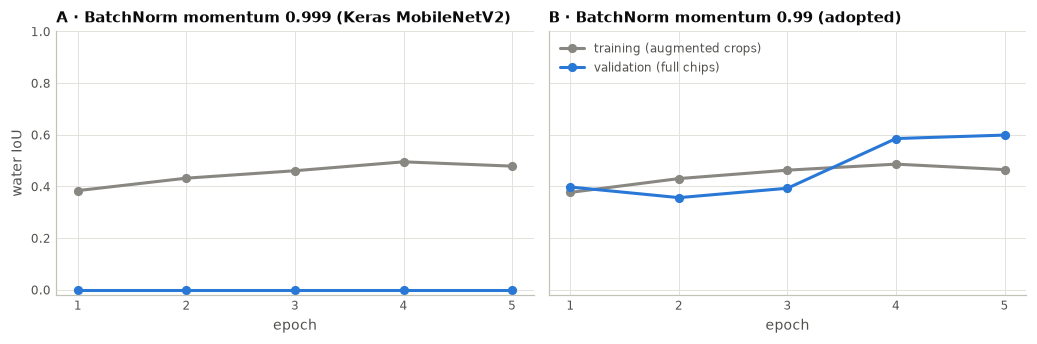

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.2), sharey=True)
for ax, key, name in ((axes[0], "A", "A · BatchNorm momentum 0.999 (Keras MobileNetV2)"),
                      (axes[1], "B", "B · BatchNorm momentum 0.99 (adopted)")):
    h = hist[key]
    ax.plot(h["epoch"] + 1, h["water_iou"], color=viz.GREY, marker="o", markersize=5, label="training (augmented crops)")
    ax.plot(h["epoch"] + 1, h["val_water_iou"], color=viz.BLUE, marker="o", markersize=5, label="validation (full chips)")
    ax.set_title(name)
    ax.set_xlabel("epoch")
    ax.set_xticks(h["epoch"] + 1)
    ax.set_ylim(-0.02, 1)
axes[0].set_ylabel("water IoU")
axes[1].legend(loc="upper left")
fig.tight_layout()
viz.savefig(fig, ROOT / "figures" / "smoke_test_bn_momentum.png")
plt.show()

The training columns of A and B are almost the same, as they should be: the momentum only changes the running statistics, which training does not use (the small differences are floating-point round-off: the two models are compiled separately).
The validation columns could not be more different. With momentum 0.999 the model that is clearly learning scores **exactly 0** on validation in all five epochs and its validation loss climbs; with 0.99 validation follows training within a few epochs.

In [7]:
def check(m, h):
    return {
        "training loss went down": bool(h["loss"].iloc[-1] < h["loss"].iloc[0]),
        "no NaN in the losses": bool(np.isfinite(h[["loss", "val_loss"]].to_numpy()).all()),
        "best validation IoU": round(m["val"]["iou"], 4),
        "validation IoU above 0": bool(m["val"]["iou"] > 0),
        "seconds per epoch (median of epochs 2 to 5)": m["training"]["sec_per_epoch"],
        "seconds for epoch 1 (includes compiling or loading kernels)": m["training"]["sec_first_epoch"],
        "peak GPU memory (MB)": m["training"]["peak_gpu_memory_mb"],
        "peak host RAM of the training process (MB)": m["training"].get("peak_host_ram_mb"),
        "parameters": m["training"]["parameters"],
    }

checks = pd.DataFrame({"A (BN 0.999)": check(metrics_a, hist["A"]), "B (BN 0.99, adopted)": check(metrics_b, hist["B"])})
b = checks["B (BN 0.99, adopted)"]
assert b["training loss went down"] and b["no NaN in the losses"] and b["validation IoU above 0"]
assert b["peak GPU memory (MB)"] < 3500, "too close to the 4 GB limit"
checks

,A (BN 0.999),"B (BN 0.99, adopted)"
training loss went down,True,True
no NaN in the losses,True,True
best validation IoU,0.0,0.599
validation IoU above 0,False,True
seconds per epoch (median of epochs 2 to 5),13.52,10.73
seconds for epoch 1 (includes compiling or loading kernels),329.36,115.48
peak GPU memory (MB),618.0,622.5
peak host RAM of the training process (MB),3994,4448
parameters,5419473,5419473


## 5. Will 21 runs fit?

In [8]:
sec = metrics_b["training"]["sec_per_epoch"]
runs, max_epochs = 21, 60
overhead_min = 5.0   # allowance per run: XLA compiling or loading, saving the model, evaluation
estimate = pd.Series({
    "seconds per epoch": sec,
    "one run, all 60 epochs (min)": round(max_epochs * sec / 60, 1),
    "21 runs if every run uses all 60 epochs (h)": round(runs * (max_epochs * sec / 60 + overhead_min) / 60, 1),
    "21 runs if early stopping ends them around epoch 40 (h)": round(runs * (40 * sec / 60 + overhead_min) / 60, 1),
    "peak GPU memory (MB, of 4096)": metrics_b["training"]["peak_gpu_memory_mb"],
}, name="estimate")
estimate.to_csv(SMOKE / "time_estimate.csv", header=True)
estimate.to_frame()

,estimate
seconds per epoch,10.73
"one run, all 60 epochs (min)",10.70
21 runs if every run uses all 60 epochs (h),5.50
21 runs if early stopping ends them around epoch 40 (h),4.30
"peak GPU memory (MB, of 4096)",622.50


## 6. What the smoke test settled

* **The chain works** (run B). Loss falls, validation IoU rises, the model saved at the best epoch reloads and reproduces its validation score, and nothing ran out of memory. Peak GPU memory is about 0.6 GB of the 4 GB card, so batch 8 with 256×256 crops stays. The training process needs about 4.4 GB of host RAM, which fits WSL's 7.5 GB as long as only one run trains at a time.
* **A real problem was caught** (run A). With Keras' stock MobileNetV2 the validation IoU sits at exactly 0 while training improves, because the encoder's BatchNorm running statistics lag the weights by thousands of updates. Checkpointing, learning-rate drops and early stopping all key off the validation IoU, so with that lag they would act on noise or stop a good run for "not improving". **Fix: BatchNorm momentum 0.99 in every layer, for every model** (`"bn_momentum": 0.99` in the defaults). The decision used validation data only.
* **XLA on**, with a persistent compile cache (section 1).
* **Budget.** At about 11 seconds per epoch the full plan (7 configurations × 3 seeds, up to 60 epochs, patience 15) needs at most about 5.5 hours of GPU time, so no seeds or epochs need to be cut.